# Spectral Clustering

In [1]:
from matplotlib import pyplot as plt
from plotly.subplots import make_subplots
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

from src.data import (
    loader as data_loader,
    # sample as data_sample,
    # display_ as data_display,
)

In [2]:
pio.renderers.default = "png"

## Sklearn SpectralClustering class

We will use the class SpectralClustering from scikit learn: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.SpectralClustering.html

Used options:
- n_clusters: In our examples this argument was easy to choose as we could plot the data and determine how many clusters we wanted
- eigen_solver: we used the default methodology to determine the eigen vectors
- affinity: How to construct the affinity matrix, the methodology that gave the best result was '**nearest_neighbors**'

#### Fitting Models

In [3]:
def get_train_test_split(
    df: pd.DataFrame,
) -> dict:

    X_raw = df[["x1", "x2"]]

    # Train-Test Split
    X, X_test = train_test_split(
        X_raw,
        test_size=0.25,
        random_state=0,  # reproducibility
        shuffle=True,
    )
    dict_split = {
        "train": {"X": X},
        "test": {"X": X_test},
    }
    return dict_split


# DICT_DS_SPLIT = {n: get_train_test_split(df=dict_df_ds[n]) for n in dict_df_ds}

In [4]:
def get_fitted_models_labels(
    dict_ds: dict, 
):
    n_clusters = 3

    X_train = dict_ds["train"]["X"]

    # Spectral Clustering
    spc_model_knn = SpectralClustering(
        n_clusters=n_clusters, 
        eigen_solver="arpack",  # method to determine eigen vectors
        affinity="nearest_neighbors",  # How to construct the affinity matrix
        random_state=0,
    )

    # Gaussian mixture
    gm_model = GaussianMixture(
        n_components=n_clusters, 
        covariance_type='full',
        init_params='kmeans', 
        random_state=0,
    )

    # K-means
    kmeans = KMeans(
        n_clusters=n_clusters, 
        init='k-means++', 
        random_state=0, 
        n_init="auto", 
    )

    dict_models = {
        'spc_knn': spc_model_knn,
        'gmm': gm_model,
        'kmeans': kmeans,
    }
    dict_res = {}
    for _name, _model in dict_models.items():
        dict_res[_name] = {
            'model': _model, 
            "cluster_predicted": _model.fit_predict(X_train),
        }
        
    return dict_res

## Comparing Clustering Algorithms

### Circle Dataset

#### Load data

Read: cercles3.txt


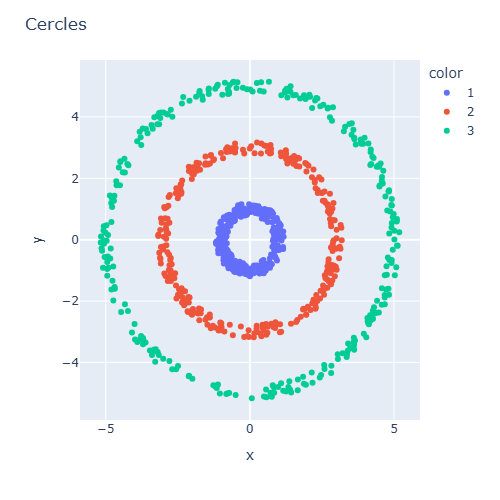

In [5]:
df_c_raw = data_loader.load_cercles_ds()
dict_ds_c = get_train_test_split(df=df_c_raw)

df_c = dict_ds_c['train']['X']

# Plot data
fig = px.line(x=df_c_raw["x1"], y=df_c_raw["x2"], color=df_c_raw["y"])
fig.update_traces(mode="markers")
fig.update_layout(title="Cercles", width=500)

#### Fit Models

In [6]:
dict_data = get_fitted_models_labels(dict_ds=dict_ds_c)
dict_data.keys()

c:\Users\aishema\Documents\CodeProjects\Education\ml-projects\.venv\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


dict_keys(['spc_knn', 'gmm', 'kmeans'])

#### Display Clusters predicted

In [7]:
dict_data.keys()

dict_keys(['spc_knn', 'gmm', 'kmeans'])

In [8]:
df_res = dict_ds_c['train']['X'].copy() 
for m in dict_data:
    df_res[f'labels_{m}'] = dict_data[m]["cluster_predicted"]

df_res.head()

,x1,x2,labels_spc_knn,labels_gmm,labels_kmeans
506,-2.043897,-2.400976,0,0,0
211,1.154772,-0.301268,1,0,0
656,-5.128029,-0.364468,2,0,0
51,0.841143,-0.327396,1,0,0
675,-3.160513,-3.757815,2,0,0


#### Compare results

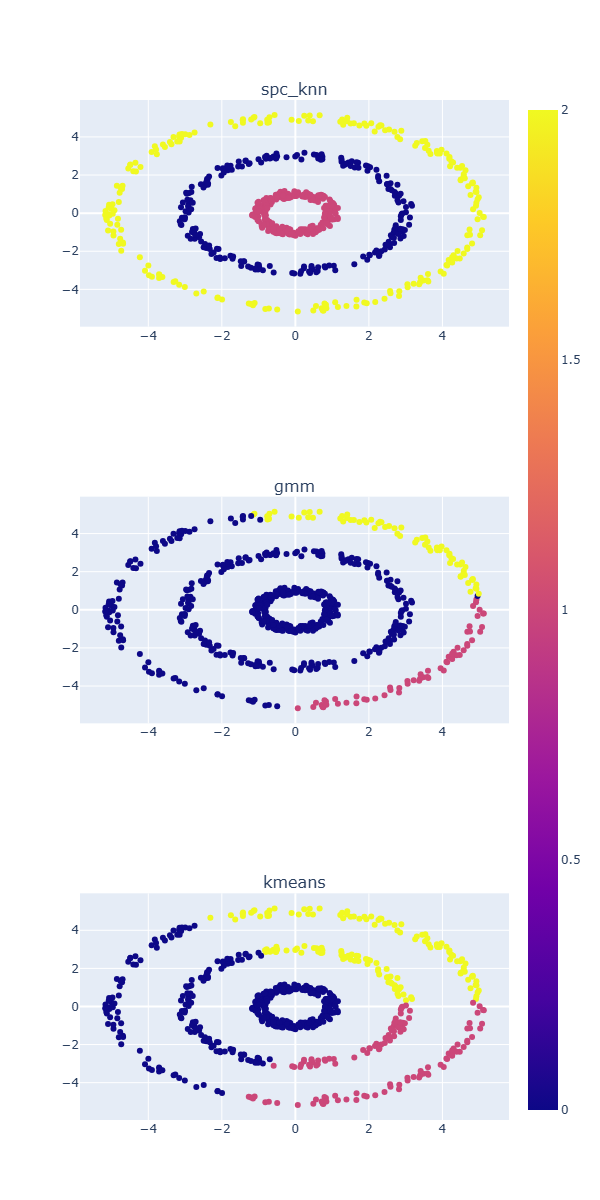

In [9]:
list_model = [m for m in dict_data]
n_rows = len(list_model )
fig = make_subplots(rows=n_rows, cols=1, subplot_titles=tuple(m for m in list_model))
idx_sp = 1
for _model in list_model :
    _fig = px.scatter(data_frame=df_res, x='x1', y='x2', color=f'labels_{_model}')
    fig.add_traces(_fig.data, rows=idx_sp, cols=1)
    idx_sp += 1

fig.update_layout(width=600, height=400 * n_rows)
fig.show()

Spectral clustering with affinity matrix computed from nearest neighbors performs quite better that the other algorithms on this dataset 